# Regression: a reversible reaction in a batch reactor

**CHME 5137, homework after Lectures 12 and 13 (October 20 and 23, 2026).** Section 5 of
the Lecture 13 notebook started this. Here it is in full.

*Written for 2026 by Claude Code (Claude Opus 5.5) from Prof. West's A ⇌ B fitting
exercise of earlier years, and checked by Prof. West.*

---

You run a reversible, first-order reaction in a batch reactor:
$$\mathrm{A} \rightleftharpoons \mathrm{B}, \qquad
\frac{dC_A}{dt} = k_r C_B - k_f C_A, \qquad C_B = C_{A,0} - C_A$$
Every run starts with $C_{A,0} = 10$ mol/L and no B. You measured $C_A$ every 10 s for
100 s, at three temperatures.

**Kinetics.** The forward rate constant follows the Arrhenius expression,
$k_f = A \exp(-E_a/RT)$.

**Thermodynamics.** At equilibrium the forward and reverse rates are equal, so the
equilibrium constant is $K = k_f/k_r$. (Assume an ideal solution, so this
concentration-based $K$ is the thermodynamic one.) From thermodynamics,
$$\Delta G^\circ = -RT\ln K \qquad\text{and}\qquad \Delta G^\circ = \Delta H - T\,\Delta S$$
A and B have very similar heat capacities, so take $\Delta H$ and $\Delta S$ to be
independent of temperature. Then $k_r = k_f/K$, and the whole model has **four
parameters**: $\log_{10} A$, $E_a$, $\Delta H$ and $\Delta S$.

Before the experiments, from the literature and a quantum chemistry calculation, your
estimates were $\log_{10}A \approx 6$ (A in s⁻¹), $E_a \approx 45$ kJ/mol,
$\Delta H \approx -10$ kJ/mol and $\Delta S \approx -50$ J/mol/K. Let's see what the data say.

### How to work

- **Commit as you go.** After each numbered task works, Restart & Run All, then commit
  with a message that says what you did, and push. At least one commit per task.
  **Commit the `.ipynb` and its paired `.py` together.**
- **Answer the questions in words**, in the markdown cells marked *Answer*.
- **Say what your ± means.** One standard error, or a 95% interval? Either is fine. Say which (Lecture 13).
- **Let bugs shout.** If `solve_ivp` fails, `raise` an error with its `message`.
  Don't let a half-finished solution reach `curve_fit` without anyone noticing.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate
import scipy.optimize
import scipy.stats

plt.rcParams['figure.figsize'] = [5, 3]
R = 8.314  # J/mol/K

The data, the same as in class:

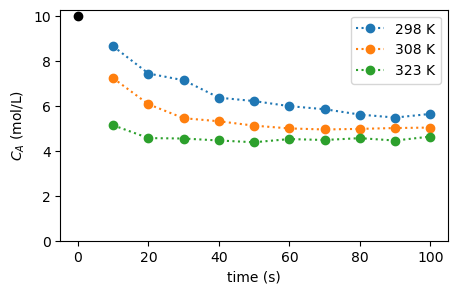

In [3]:
cA0 = 10.0   # mol/L
times = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90, 100.])   # s
cA_data = {   # mol/L, keyed by temperature in K
    298.15: np.array([8.649, 7.441, 7.141, 6.366, 6.215, 5.990, 5.852, 5.615, 5.481, 5.644]),
    308.15: np.array([7.230, 6.073, 5.452, 5.317, 5.121, 4.998, 4.951, 4.978, 5.015, 5.036]),
    323.15: np.array([5.137, 4.568, 4.548, 4.461, 4.382, 4.525, 4.483, 4.565, 4.459, 4.635]),
}
temperatures = np.array(list(cA_data))

for T, cA in cA_data.items():
    plt.plot(times, cA, 'o:', label=f'{T:.0f} K')
plt.plot(0, cA0, 'ko')
plt.xlabel('time (s)')
plt.ylabel('$C_A$ (mol/L)')
plt.ylim(0, None)
plt.legend()
plt.show()

## 1. One temperature

**(a) The model.** Write `cA_model(times, kf, kr)`, which solves the ODE with
`scipy.integrate.solve_ivp` and returns $C_A$ at `times` (use `t_eval`). In Lecture 13 we fitted
functions that were a formula. `curve_fit` doesn't care: any function that takes the
independent variable first and then the parameters, and returns predictions, will do. Even
one that runs a whole simulation.

Then **test it** (Lecture 11). This ODE has an exact solution,
$$C_A(t) = C_{A,\mathrm{eq}} + (C_{A,0} - C_{A,\mathrm{eq}})\,e^{-(k_f+k_r)t},
\qquad C_{A,\mathrm{eq}} = C_{A,0}\frac{k_r}{k_f+k_r}$$
Check that your function agrees with it, for some reasonable $k_f$ and $k_r$, with an
`assert`. (We use `solve_ivp` anyway because your project's model won't have an exact
solution.)

In [13]:
def cA_model(times, kf, kr):
    """C_A (mol/L) at the requested times (s), for kf, kr in 1/s."""
    times = np.asarray(times, dtype=float)
    if times.ndim != 1:
        raise ValueError("times must be a one-dimensional array")
    if np.any(times < 0):
        raise ValueError("Measurement times cannot be negative")
    if kf < 0 or kr < 0:
        raise ValueError("Rate constants must be nonnegative")
    if times.size == 0:
        return np.array([], dtype=float)
    if np.max(times) == 0:
        return np.full(times.shape, cA0)

    # solve_ivp needs increasing t_eval
    unique_times, original_order = np.unique(times, return_inverse=True)

    def rhs(t, y):
        CA = y[0]
        CB = cA0 - CA
        return [kr * CB - kf * CA]

    solution = scipy.integrate.solve_ivp(
        rhs, (0, float(unique_times[-1])), [cA0],
        t_eval=unique_times, rtol=1e-8, atol=1e-10
    )
    if not solution.success:
        raise RuntimeError(f"solve_ivp failed: {solution.message}")
    return solution.y[0][original_order]


t_test = np.array([0., 5., 10., 20., 50., 100.])
kf_test, kr_test = 0.03, 0.02  # 1/s
Ceq_test = cA0 * kr_test / (kf_test + kr_test)
CA_exact = Ceq_test + (cA0 - Ceq_test) * np.exp(-(kf_test + kr_test) * t_test)
CA_numerical = cA_model(t_test, kf_test, kr_test)
assert np.allclose(CA_numerical, CA_exact, rtol=1e-6, atol=1e-7)
print("Task 1a: ODE solution agrees with analytical solution.")


Task 1a: ODE solution agrees with analytical solution.


**(b) Fit it at 298.15 K**, with `scipy.optimize.curve_fit`. **Try it without `p0` first.**
It may fail with an error from deep inside SciPy, or it may appear to succeed. Either way,
find out what happened: print and plot what came back, or what `cA_model` returns
at `curve_fit`'s default starting point. Then give it a starting guess you can justify
from the data. Roughly how long does $C_A$ take to get halfway to where it ends up?

Fit without p0 failed: ValueError Rate constants must be nonnegative
Predictions at default p0=(1,1): [5. 5. 5. 5. 5. 5. 5. 5. 5. 5.]


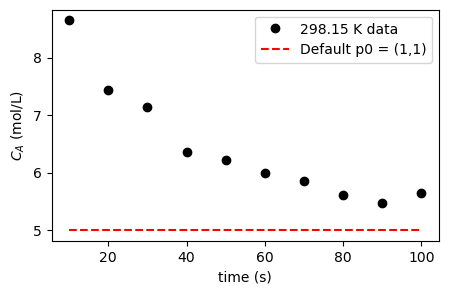

In [14]:
import warnings
try:
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        default_fit, default_cov = scipy.optimize.curve_fit(
            cA_model, times, cA_data[298.15], maxfev=3000
        )
    print("Default fit parameters:", default_fit)
    print("Default fit predicted concentrations:", cA_model(times, *default_fit))
    for warning in caught:
        print("Warning:", warning.message)
except (ValueError, RuntimeError, TypeError) as error:
    print("Fit without p0 failed:", type(error).__name__, error)

# Either way, inspect the poor default starting prediction.
initial_default = cA_model(times, 1.0, 1.0)
print("Predictions at default p0=(1,1):", np.round(initial_default, 3))
plt.plot(times, cA_data[298.15], 'ko', label='298.15 K data')
plt.plot(times, initial_default, 'r--', label='Default p0 = (1,1)')
plt.xlabel('time (s)')
plt.ylabel('$C_A$ (mol/L)')
plt.legend()
plt.show()


In [15]:
# The late-time measurements are near C_A,eq ~= 5.5 mol/L.
# Halfway from 10 to 5.5 is 7.75 mol/L
Ceq_guess = 5.5
half_time_guess = 18.0  # s
rate_sum_guess = np.log(2) / half_time_guess  # kf + kr
kr_guess = rate_sum_guess * Ceq_guess / cA0
kf_guess = rate_sum_guess - kr_guess
print(f"Starting guess: kf={kf_guess:.5f}, kr={kr_guess:.5f} 1/s")

popt_298, pcov_298 = scipy.optimize.curve_fit(
    cA_model, times, cA_data[298.15],
    p0=[kf_guess, kr_guess], bounds=(0, np.inf), maxfev=20000
)
perr_298 = np.sqrt(np.diag(pcov_298))  # 1 standard error
for name, value, sd in zip(('kf', 'kr'), popt_298, perr_298):
    print(f"298.15 K: {name} = {value:.6f} ± {sd:.6f} 1/s (1 SE)")


Starting guess: kf=0.01733, kr=0.02118 1/s
298.15 K: kf = 0.016799 ± 0.000786 1/s (1 SE)
298.15 K: kr = 0.020064 ± 0.001543 1/s (1 SE)


**(c) Look at it.** Plot the data and the fitted curve, and below it the residuals
(data minus model). Report $k_f$ and $k_r$ with their uncertainties.

What happened without `p0`, and why? What starting guess did you use, and how did you
choose it?

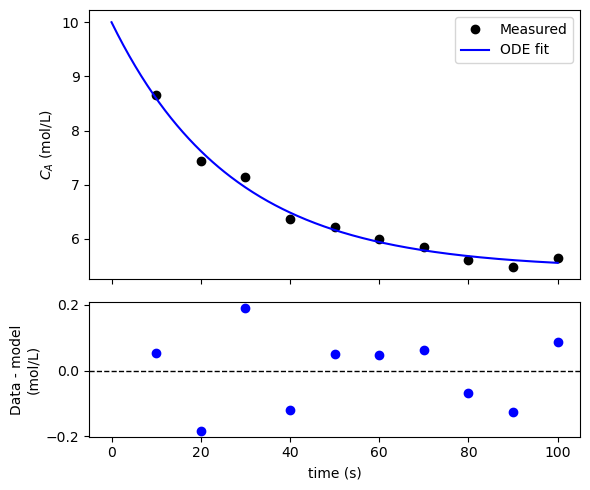

In [16]:
t_dense = np.linspace(0, 100, 301)
model_298 = cA_model(times, *popt_298)
residual_298 = cA_data[298.15] - model_298
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(6, 5),
                         gridspec_kw={'height_ratios': [2, 1]})
axes[0].plot(times, cA_data[298.15], 'ko', label='Measured')
axes[0].plot(t_dense, cA_model(t_dense, *popt_298), 'b-', label='ODE fit')
axes[0].set_ylabel('$C_A$ (mol/L)')
axes[0].legend()
axes[1].plot(times, residual_298, 'bo')
axes[1].axhline(0, color='k', linestyle='--', linewidth=1)
axes[1].set_xlabel('time (s)')
axes[1].set_ylabel('Data - model\n(mol/L)')
plt.tight_layout()
plt.show()

*Answer:*
The numerical solution obtained using `solve_ivp` agrees with the analytical solution for the reversible first-order reaction, as confirmed by the assertion test.

When `curve_fit` was used without specifying `p0`, it started with default values of kf = kr = 1 s⁻¹. These values predict a rapid approach to an equilibrium concentration of approximately 5 mol/L, which does not match the early experimental measurements. With validation of nonnegative rate constants, the unconstrained fit failed when it attempted a negative rate constant.

To obtain a reasonable initial guess, I estimated the equilibrium concentration as approximately 5.5 mol/L and the half-time as 18 seconds. This gave initial guesses of kf = 0.0173 s⁻¹ and kr = 0.0212 s⁻¹.

Using these initial guesses, the fitted rate constants at 298.15 K were:

- kf = 0.01680 ± 0.00079 s⁻¹
- kr = 0.02006 ± 0.00154 s⁻¹

The uncertainties represent one standard error from the fitted covariance matrix, not 95% confidence intervals. The fitted curve follows the experimental measurements closely, and the residuals fluctuate around zero.


## 2. Three temperatures, in two steps

**(a)** Fit $k_f$ and $k_r$ separately at each temperature, and make a small table of
$k_f$, $k_r$ (each with its ±) and $K = k_f/k_r$.

**Before fitting anything else:** from your $K$ values alone, is the reaction endothermic
or exothermic? How can you tell?

In [17]:

start_by_T = {
    298.15: popt_298,
    308.15: [0.04, 0.04],
    323.15: [0.12, 0.10]
}

fits_by_T = {}

print(f"{'T (K)':>9}  {'kf (1/s) +/- SE':>24}  {'kr (1/s) +/- SE':>24}  {'K +/- SE':>19}")

for T in temperatures:

    p, cov = scipy.optimize.curve_fit(
        cA_model,
        times,
        cA_data[T],
        p0=start_by_T[T],
        bounds=(0, np.inf),
        maxfev=20000
    )

    sd = np.sqrt(np.diag(cov))

    kf, kr = p
    K = kf / kr

    # Propagate uncertainty in K using the covariance
    gradient_K = np.array([1 / kr, -kf / kr**2])
    sd_K = np.sqrt(gradient_K @ cov @ gradient_K)

    fits_by_T[T] = {
        "p": p,
        "cov": cov,
        "se": sd,
        "K": K,
        "se_K": sd_K
    }

    print(
        f"{T:9.2f}  "
        f"{kf:9.6f} +/- {sd[0]:8.6f}  "
        f"{kr:9.6f} +/- {sd[1]:8.6f}  "
        f"{K:8.4f} +/- {sd_K:7.4f}"
    )

kf_array = np.array([
    fits_by_T[T]["p"][0] for T in temperatures
])

kr_array = np.array([
    fits_by_T[T]["p"][1] for T in temperatures
])

K_array = kf_array / kr_array

print("Because K increases with temperature,")
print("the forward reaction is endothermic.")


    T (K)           kf (1/s) +/- SE           kr (1/s) +/- SE             K +/- SE
   298.15   0.016799 +/- 0.000786   0.020064 +/- 0.001543    0.8373 +/-  0.0306
   308.15   0.039260 +/- 0.000854   0.039249 +/- 0.001060    1.0003 +/-  0.0092
   323.15   0.118945 +/- 0.006415   0.097517 +/- 0.005620    1.2197 +/-  0.0123
Because K increases with temperature,
the forward reaction is endothermic.


**(b) Arrhenius.** As in Lecture 13: `scipy.stats.linregress` on $\ln k_f$ against
$1/T$ gives $E_a$ from the slope and $\ln A$ from the intercept. Convert $\ln A$ to
$\log_{10} A$.

**(c) van 't Hoff.** Put the two expressions for $\Delta G^\circ$ together and divide by $-RT$:
$$\ln K = -\frac{\Delta H}{R}\,\frac{1}{T} + \frac{\Delta S}{R}$$
So $\ln K$ against $1/T$ is a straight line too, with slope $-\Delta H/R$ and intercept
$\Delta S/R$. Fit it, and get $\Delta H$ and $\Delta S$, with their ±. Does the sign of
$\Delta H$ agree with what you said in (a)?

Task 2: Estimated parameters
log10(A) = 9.2012 +/- 0.1724
Ea = 62.6207 +/- 1.0208 kJ/mol
Delta H = 11.9875 +/- 0.7359 kJ/mol
Delta S = 38.7936 +/- 2.3791 J/mol/K


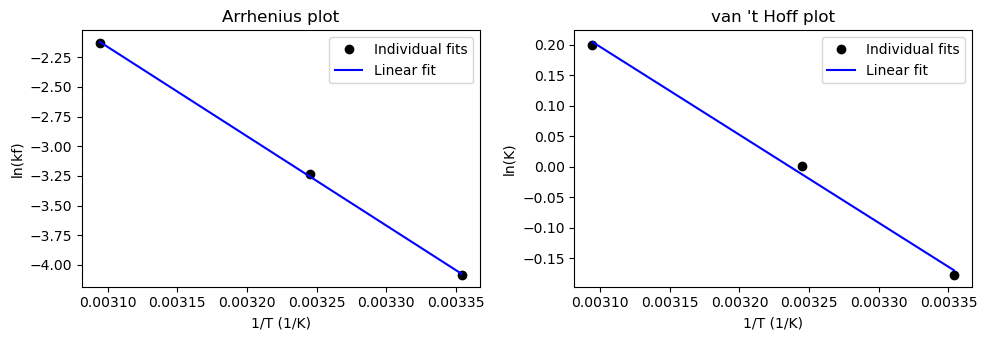

In [18]:

x_invT = 1 / temperatures

arr = scipy.stats.linregress(
    x_invT, np.log(kf_array)
)

vh = scipy.stats.linregress(
    x_invT, np.log(K_array)
)

# Convert slopes and intercepts into parameters
log10A_2 = arr.intercept / np.log(10)

Ea_2 = -arr.slope * R / 1000

dH_2 = -vh.slope * R / 1000

dS_2 = vh.intercept * R

# One-standard-error uncertainties
se_log10A_2 = arr.intercept_stderr / np.log(10)

se_Ea_2 = arr.stderr * R / 1000

se_dH_2 = vh.stderr * R / 1000

se_dS_2 = vh.intercept_stderr * R

popt_2 = np.array([
    log10A_2, Ea_2, dH_2, dS_2
])

perr_2 = np.array([
    se_log10A_2, se_Ea_2, se_dH_2, se_dS_2
])

print("Task 2: Estimated parameters")

print(
    f"log10(A) = {log10A_2:.4f} +/- "
    f"{se_log10A_2:.4f}"
)

print(
    f"Ea = {Ea_2:.4f} +/- "
    f"{se_Ea_2:.4f} kJ/mol"
)

print(
    f"Delta H = {dH_2:.4f} +/- "
    f"{se_dH_2:.4f} kJ/mol"
)

print(
    f"Delta S = {dS_2:.4f} +/- "
    f"{se_dS_2:.4f} J/mol/K"
)

# Plot the Arrhenius and van 't Hoff fits
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

axes[0].plot(
    x_invT, np.log(kf_array), "ko",
    label="Individual fits"
)

axes[0].plot(
    x_invT,
    arr.intercept + arr.slope * x_invT,
    "b-", label="Linear fit"
)

axes[0].set_xlabel("1/T (1/K)")
axes[0].set_ylabel("ln(kf)")
axes[0].set_title("Arrhenius plot")
axes[0].legend()

axes[1].plot(
    x_invT, np.log(K_array), "ko",
    label="Individual fits"
)

axes[1].plot(
    x_invT,
    vh.intercept + vh.slope * x_invT,
    "b-", label="Linear fit"
)

axes[1].set_xlabel("1/T (1/K)")
axes[1].set_ylabel("ln(K)")
axes[1].set_title("van 't Hoff plot")
axes[1].legend()

plt.tight_layout()
plt.show()


**(d)** `linregress` gave you a ± on each of these. What does that ± know about,
and what has it left out? Think about how many points each straight line had, and about
the ± you got in (a).

*Answer:*
**(a) Reaction behavior at three temperatures**

The forward and reverse reaction rate constants were independently fitted at 298.15 K, 308.15 K, and 323.15 K. The equilibrium constants were approximately 0.837, 1.000, and 1.220, respectively.

Since the equilibrium constant increases with temperature, the forward reaction A → B is endothermic. Increasing the temperature favors the formation of product B.

**(b) Arrhenius analysis**

The Arrhenius equation was linearized by plotting ln(kf) against 1/T. Linear regression gave:

- log10(A) = 9.201 ± 0.172, with A expressed in s⁻¹
- Ea = 62.621 ± 1.021 kJ/mol

The negative slope of the Arrhenius plot was used to calculate the activation energy.

**(c) van 't Hoff analysis**

Linear regression of ln(K) against 1/T gave:

- Delta H = +11.988 ± 0.736 kJ/mol
- Delta S = +38.794 ± 2.379 J/mol/K

The positive enthalpy change confirms that the forward reaction is endothermic, consistent with the increase in equilibrium constant with temperature.

**(d) Interpretation of uncertainties**

The uncertainties reported by linregress represent one standard error estimated from the scatter of the three fitted points around each straight line, assuming the linear model is appropriate.

However, these uncertainties do not directly propagate the errors in the forward and reverse rate constants obtained from fitting the original concentration measurements. The correlations between the fitted rate constants are also not carried through to the Arrhenius and van 't Hoff regressions.

Additionally, each regression uses only three temperature points, leaving one residual degree of freedom. Therefore, the estimated uncertainties are sensitive to the small dataset and may not represent the complete uncertainty in the physical parameters. A simultaneous fit to all 30 concentration measurements would provide a more direct uncertainty analysis.


## 3. All the data at once

Step 2 fitted 3 × 2 rate constants, then fitted lines through three points each. Better:
fit the four parameters you actually want **directly to all 30 measurements**, so that
every measurement counts and the uncertainties carry all the way through.

`curve_fit` wants one `xdata` and one `ydata`. With several experiments, stack them:
`ydata` is all 30 concentrations in one array, and `xdata` carries **both** the
temperature and the time of each one. `curve_fit` never looks inside `xdata`; it just passes it
to your function. So it can be a tuple of two arrays:

In [ ]:
T_all = np.repeat(temperatures, len(times))     # 298.15 ten times, then 308.15 ten times, ...
t_all = np.tile(times, len(temperatures))        # 10, 20, ..., 100, three times over
cA_all = np.concatenate([cA_data[T] for T in temperatures])
x_all = (T_all, t_all)
print(T_all[:12], t_all[:12], cA_all[:12], sep='\n')

**(a)** Write `cA_model_all(x, log10A, Ea, dH, dS)`. Unpack `x` into temperatures and
times. For each temperature, work out $k_f$, $K$ and $k_r$, then call your `cA_model` for
that temperature's times, and put the results in the right places of the output array.
Solve one ODE per temperature, not one per data point. A boolean mask such as
`T_col == T` picks out the rows.

Notice the **units**: $E_a$ and $\Delta H$ in kJ/mol, $\Delta S$ in J/mol/K, and $A$ as
$\log_{10}A$. That keeps all four parameters between about 1 and 100. An optimizer
has an easier time when its parameters are all a similar size than when one is
$10^{9}$ and another is $10^{-2}$. So convert carefully inside the function.

Then fit it, **starting from your answers to task 2**, and report the four parameters with
their ±.

In [25]:

def cA_model_all(x, log10A, Ea, dH, dS):
    """Predict C_A for all temperature-time pairs."""

    T_col, t_col = x

    T_col = np.asarray(T_col, dtype=float)
    t_col = np.asarray(t_col, dtype=float)

    if T_col.shape != t_col.shape:
        raise ValueError("Temperature and time arrays must match")

    predictions = np.empty_like(t_col, dtype=float)

    for T in np.unique(T_col):
        mask = (T_col == T)

        # Arrhenius equation
        kf = 10**log10A * np.exp(
            -Ea * 1000 / (R * T)
        )

        # van 't Hoff equation
        K = np.exp(
            -dH * 1000 / (R * T) + dS / R
        )

        # Reverse rate constant
        kr = kf / K

        predictions[mask] = cA_model(
            t_col[mask], kf, kr
        )

    return predictions


In [27]:

T_all = np.repeat(temperatures, len(times))
t_all = np.tile(times, len(temperatures))

cA_all = np.concatenate([
    cA_data[T] for T in temperatures
])

x_all = (T_all, t_all)

print("Total measurements:", len(cA_all))

# Starting guesses from Task 2
initial_guess = [9.2012, 62.6207, 11.9875, 38.7936]

physical_bounds = (
    [-2, 0, -100, -500],
    [20, 200, 100, 500]
)

# Fit all experimental data
popt_joint, pcov_joint = scipy.optimize.curve_fit(
    cA_model_all,
    x_all,
    cA_all,
    p0=initial_guess,
    bounds=physical_bounds,
    maxfev=20000
)

# Calculate standard errors
perr_joint = np.sqrt(np.diag(pcov_joint))

parameter_names = [
    "log10(A)",
    "Ea (kJ/mol)",
    "Delta H (kJ/mol)",
    "Delta S (J/mol/K)"
]

print("\nTask 3: Joint parameter estimation")

for name, value, error in zip(
    parameter_names, popt_joint, perr_joint
):
    print(f"{name}: {value:.4f} +/- {error:.4f}")


Total measurements: 30

Task 3: Joint parameter estimation
log10(A): 9.4885 +/- 0.3672
Ea (kJ/mol): 64.3078 +/- 2.1377
Delta H (kJ/mol): 11.5315 +/- 0.7905
Delta S (J/mol/K): 37.3495 +/- 2.5129


**(b)** Now start from your estimates from before the experiments instead (6, 45, −10, −50).
Does it find the same answer? How far did the data move you from what you expected?

In [28]:

prior_guess = np.array([6.0, 45.0, -10.0, -50.0])

popt_prior, pcov_prior = scipy.optimize.curve_fit(
    cA_model_all,
    x_all,
    cA_all,
    p0=prior_guess,
    bounds=physical_bounds,
    maxfev=20000
)

print("Fit starting from Task 2 estimates:")
print(np.round(popt_joint, 4))

print("\nFit starting from original estimates:")
print(np.round(popt_prior, 4))

same_answer = np.allclose(
    popt_joint,
    popt_prior,
    rtol=0,
    atol=1e-3
)

print("\nDo both fits agree?", same_answer)

# Compare with original estimates
print("\nChanges from original estimates:")

for name, old, new in zip(
    parameter_names, prior_guess, popt_prior
):
    print(f"{name}: {new - old:+.4f}")


Fit starting from Task 2 estimates:
[ 9.4885 64.3078 11.5315 37.3495]

Fit starting from original estimates:
[ 9.4885 64.3078 11.5315 37.3495]

Do both fits agree? True

Changes from original estimates:
log10(A): +3.4885
Ea (kJ/mol): +19.3078
Delta H (kJ/mol): +21.5315
Delta S (J/mol/K): +87.3495


**(c)** Compare with task 2. Are the centres the same? Are the error bars? Which set of
error bars would you believe, and why?

**(d) The correlation matrix.** The off-diagonal elements of `pcov` say how the errors in
the parameters go together (Lecture 13). Turn the covariance into correlations:
`pcov / np.outer(perr, perr)`. Which pairs are strongly correlated? Why those pairs?
(Think about Lecture 13's ridge, and about the range of temperatures you measured over.)
If someone quotes only your four ± values, what are they missing?

Comparison of Task 2 and Task 3
Uncertainties are one standard error

log10(A)
Task 2: 9.2012 +/- 0.1724
Task 3: 9.4885 +/- 0.3672

Ea (kJ/mol)
Task 2: 62.6207 +/- 1.0208
Task 3: 64.3078 +/- 2.1377

Delta H (kJ/mol)
Task 2: 11.9875 +/- 0.7359
Task 3: 11.5315 +/- 0.7905

Delta S (J/mol/K)
Task 2: 38.7936 +/- 2.3791
Task 3: 37.3495 +/- 2.5129

Parameter correlation matrix:
[[ 1.      0.9997 -0.3627 -0.3653]
 [ 0.9997  1.     -0.3734 -0.3757]
 [-0.3627 -0.3734  1.      0.9996]
 [-0.3653 -0.3757  0.9996  1.    ]]


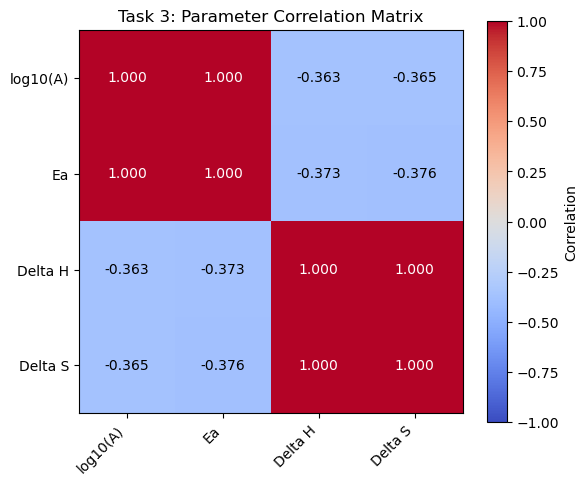

In [29]:

print("Comparison of Task 2 and Task 3")
print("Uncertainties are one standard error")

for i, name in enumerate(parameter_names):

    print(f"\n{name}")

    print(
        f"Task 2: {popt_2[i]:.4f} +/- {perr_2[i]:.4f}"
    )

    print(
        f"Task 3: {popt_joint[i]:.4f} +/- "
        f"{perr_joint[i]:.4f}"
    )

correlation = pcov_joint / np.outer(
    perr_joint, perr_joint
)

print("\nParameter correlation matrix:")
print(np.round(correlation, 4))

# Plot correlation matrix
fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(
    correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

labels = [
    "log10(A)",
    "Ea",
    "Delta H",
    "Delta S"
]

ax.set_xticks(np.arange(4))
ax.set_yticks(np.arange(4))

ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticklabels(labels)

for i in range(4):
    for j in range(4):

        ax.text(
            j, i,
            f"{correlation[i, j]:.3f}",
            ha="center",
            va="center",
            color="white" if abs(correlation[i, j]) > 0.65
            else "black"
        )

plt.colorbar(im, ax=ax, label="Correlation")

ax.set_title("Task 3: Parameter Correlation Matrix")

plt.tight_layout()
plt.show()


*Answer:*
**(a) Simultaneous parameter estimation**

All 30 experimental concentration measurements were fitted simultaneously using the Arrhenius equation, the van 't Hoff equation, and the batch reactor ODE model.

The estimated parameters were:

- log10(A) = 9.4885 ± 0.3672, with A in s⁻¹
- Ea = 64.3078 ± 2.1377 kJ/mol
- Delta H = +11.5315 ± 0.7905 kJ/mol
- Delta S = +37.3495 ± 2.5129 J/mol/K

The uncertainties represent one standard error from the covariance matrix.

**(b) Effect of the starting estimates**

The fitting was repeated using the original estimates (6, 45, -10, -50). Both sets of starting values converged to essentially the same fitted parameters.

Compared with the original estimates, log10(A) increased by approximately 3.49, Ea increased by 19.31 kJ/mol, Delta H increased by 21.53 kJ/mol, and Delta S increased by 87.35 J/mol/K.

This demonstrates that the experimental data provided substantially different parameter estimates from the initial predictions.

**(c) Comparison with Task 2**

The fitted parameter values from Tasks 2 and 3 are similar but not identical. The uncertainties are also different because the two methods use the experimental data differently.

Task 2 involved separate kinetic fits followed by linear regressions at only three temperatures. The uncertainties in the original rate constants were not directly propagated through those regressions.

Task 3 simultaneously fitted all 30 measurements. I would place more confidence in the Task 3 uncertainty estimates because they directly account for the concentration data and the covariance of the four fitted parameters. However, these estimates still depend on the validity of the model and measurement-error assumptions.

**(d) Parameter correlation analysis**

The correlation matrix shows strong positive correlations between log10(A) and Ea (approximately 0.9997), and between Delta H and Delta S (approximately 0.9996).

The strong correlation between log10(A) and Ea occurs because changes in activation energy can be compensated by changes in the pre-exponential factor.

Similarly, Delta H and Delta S can compensate for each other in the van 't Hoff equation.

These correlations are strong because the experiments cover a relatively narrow temperature range from 298.15 K to 323.15 K.

Reporting only the four individual parameter uncertainties does not show how parameter errors are related. The correlation matrix provides additional information about these dependencies.


## 4. Look at the residuals

**Always look at the residuals** (Lecture 13). Plot the residuals of the task 3 fit against
time, one colour per temperature, with a line at zero.

- Do you see a pattern, or does it look like noise?
- Is the scatter about the same width at all three temperatures? Least squares assumed it is.
- Nobody told you the measurement uncertainty, so `curve_fit` (with
  `absolute_sigma=False`, the default) estimated it from the scatter of the residuals.
  Work out that estimate yourself:
  $s = \sqrt{\sum_i r_i^2 / (N - p)}$, with $N$ data points and $p$ parameters. What does
  it say about how precisely $C_A$ was measured?
- Suppose the experimentalist now tells you their instrument is good to ±0.01 mol/L.
  What would that tell you about your model, or about the experiment?

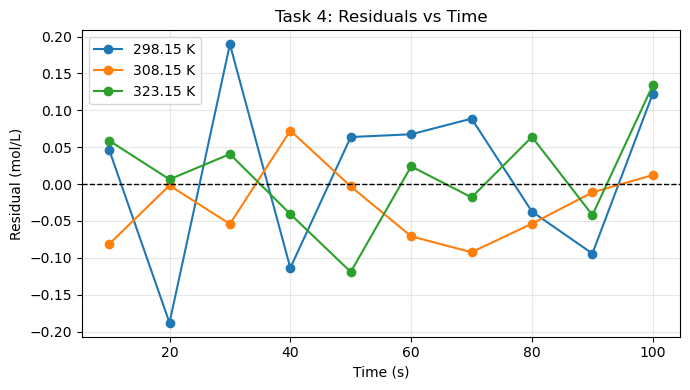

Task 4: Residual Analysis
Number of measurements: 30
Number of fitted parameters: 4
Residual sum of squares: 0.205433
Estimated measurement scatter: 0.088889 mol/L

Residual scatter at each temperature:
298.15 K: RMS = 0.113214 mol/L
308.15 K: RMS = 0.056174 mol/L
323.15 K: RMS = 0.067604 mol/L

Instrument precision: +/- 0.01 mol/L
Residual scatter / instrument precision: 8.89


In [30]:

predicted_all = cA_model_all(x_all, *popt_joint)

# Residuals = experimental data - predicted data
residual_all = cA_all - predicted_all

# Plot residuals for each temperature
fig, ax = plt.subplots(figsize=(7, 4))

for T in temperatures:
    mask = (T_all == T)

    ax.plot(
        t_all[mask],
        residual_all[mask],
        "o-",
        label=f"{T:.2f} K"
    )

# Zero reference line
ax.axhline(
    0, color="black",
    linestyle="--",
    linewidth=1
)

ax.set_xlabel("Time (s)")
ax.set_ylabel("Residual (mol/L)")
ax.set_title("Task 4: Residuals vs Time")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# Estimate standard deviation from residuals
N = len(cA_all)
p = len(popt_joint)

RSS = np.sum(residual_all**2)
s = np.sqrt(RSS / (N - p))

print("Task 4: Residual Analysis")
print("Number of measurements:", N)
print("Number of fitted parameters:", p)
print(f"Residual sum of squares: {RSS:.6f}")
print(f"Estimated measurement scatter: {s:.6f} mol/L")


# Compare residual scatter at each temperature
print("\nResidual scatter at each temperature:")

for T in temperatures:
    mask = (T_all == T)

    residual_T = residual_all[mask]

    rms_T = np.sqrt(np.mean(residual_T**2))

    print(f"{T:.2f} K: RMS = {rms_T:.6f} mol/L")


# Compare residual scatter with instrument precision
instrument_precision = 0.01

print("\nInstrument precision: +/- 0.01 mol/L")
print(
    "Residual scatter / instrument precision:",
    round(s / instrument_precision, 2)
)


*Answer:*
**Residual patterns**

The residuals were calculated as the difference between the experimental concentrations and the concentrations predicted by the simultaneous model from Task 3.

The residuals fluctuate around zero without a clear systematic trend with time. This suggests that the model captures the main concentration changes reasonably well. However, random-looking residuals alone do not prove that the model is correct.

**Comparison of residual scatter**

The residual scatter is not exactly the same at all three temperatures. The RMS residuals are approximately 0.1132 mol/L at 298.15 K, 0.0562 mol/L at 308.15 K, and 0.0676 mol/L at 323.15 K.

The 298.15 K measurements show greater scatter than the other two temperatures. This suggests that the assumption of equal measurement variance may not be completely appropriate. However, there are only ten measurements at each temperature, so more data would be needed to establish whether the difference is significant.

**Estimated measurement uncertainty**

Using the residual sum of squares and accounting for the four fitted parameters:

s = sqrt(RSS / (N - p))

where N = 30, p = 4, and RSS = 0.205433.

The estimated residual standard deviation is:

s = 0.088889 mol/L

This means the typical difference between the measured and predicted concentrations is approximately 0.089 mol/L, assuming the model is appropriate and the measurement errors are independent with equal variance.

**Comparison with instrument precision**

If the instrument has an accuracy of ±0.01 mol/L, this is much smaller than the observed residual scatter of approximately 0.089 mol/L.

The residual scatter is about 8.9 times the stated instrument precision. Therefore, instrument precision alone is unlikely to explain the observed variation.

The additional scatter could result from experimental variability, uncontrolled operating conditions, limitations of the kinetic model, or other sources of measurement error.

Additional experiments and residual analysis would help determine whether the model needs improvement or whether the experimental procedure introduces additional variation.


## 5. Your project

One paragraph. Which parameters in your project's model will come from fitting data, and
where will the data come from: your own simulations, the literature, a research group? What
can you say about the errors in those data? Are they the same absolute size, the same
relative size, or known point by point? And are any of your parameters likely to be
correlated, the way $E_a$ and $A$ are here?

*Answer:*

## Stretch problems (optional)

**(a) Untangle the ridge.** Write $k_f$ in terms of its value at a reference temperature in
the middle of your data, say $T_\mathrm{ref} = 310$ K:
$$k_f(T) = k_\mathrm{ref}\exp\left[-\frac{E_a}{R}\left(\frac{1}{T} - \frac{1}{T_\mathrm{ref}}\right)\right]$$
It's the same model, written differently. Fit $\log_{10}k_\mathrm{ref}$, $E_a$, $\Delta H$
and $\Delta S$, and look at the correlation matrix again. What changed, and why? Can you do
the same for $\Delta H$ and $\Delta S$?

**(b) Draw the posterior.** At 298.15 K only, put $k_f$ and $k_r$ on a 2-D grid and draw
their posterior, as in Lecture 13, part 5, with a flat prior and Gaussian errors of width
$s$ from task 4. Do its 95% credible intervals (summed over the other parameter) agree with
`curve_fit`'s 95% confidence intervals? Why should they, or why not?

---

### When you're done

Restart & Run All. Check that every cell ran, in order, with no errors, and that the plots
are there. Commit and push. Then check on GitHub that your fork shows your latest commit.